# NB-03 · Stage 4 — Gating network (v2: tuned + ensembled)

**Project:** hierarchical distillation for 12-lead ECG (PTB-XL, 100 Hz)
**Runtime:** Kaggle, T4 (a CPU would do as well: the whole notebook works on cached 256-d vectors and takes a few minutes)

The gating network looks at the frozen DEAN embedding of an ECG and says which of the five departments (NORM, MI, STTC, CD, HYP) it belongs to. It is a small MLP (256 → 256 → 5, 67,077 parameters). It is only a **training-time** component: NB-07 stores its outputs as a distillation target for the Chief Resident, and nothing at inference time routes through it.

### Input
| Kaggle Dataset | Files used |
|---|---|
| `dean-finetuned-v2` (NB-02, revision 2) | `dean_emb_train.npy`, `dean_emb_val.npy`, `split_idx.npz`, `eval_lib.py`, `calibration.json`, `dean_logits_val.npy`, `dean_logits_train.npy`, `dean_logits_train_oof.npy` |
| `ptbxl-processed-v1` (Stage 1) | `labels_multihot.csv` (labels and folds), `ptbxl_100hz.npy` (only to draw example ECGs) |

The SSL notebook output (`dean-ssl-pretrained-v1`) is **not** needed here, and neither is `dean_lib.py`: the encoder is never run again.

### Output (`/kaggle/working`)
| File | Used by |
|---|---|
| `gating.pt`, `gating_lib.py` | NB-07 (cache), NB-08 (Chief Resident), NB-09 (test evaluation) |
| `routing_distributions.npy` (N_train × 5) | NB-07 and NB-08: the cross-fitted routing distribution g(x) of every training record |
| `routing_distributions_insample.npy`, `routing_probs_*.npy`, `routing_val.npy` | analysis, NB-07 |
| `gating_metrics.json`, `gating_val_table.csv/.tex`, `gating_per_dept.csv`, `gating_ablation.csv`, `gating_generalisation_gap.csv` | paper tables |
| `figures/*.png, *.pdf` | paper figures |

All arrays use the row order of `split_idx.npz` (training records in `train_idx` order, validation records in `val_idx` order). Fold usage: folds 1-8 train, fold 9 validation, **fold 10 is not touched**.

### Decisions that depart from, or interpret, the planning doc
* **Multi-label BCE**, not cross-entropy: 3,526 training records carry two or more superclass labels, and 1,129 carry none.
* **Two outputs, not one.** The network produces department membership probabilities `p = sigmoid(logits)`, trained with BCE and used for all classification metrics. The routing distribution that later notebooks mimic is derived from them, `g = (p + ε) / Σ(p + ε)` with ε = 0.02. A record that really is MI + STTC then splits its mass over those two departments, and a record the gate cannot place ends up near uniform instead of arbitrarily sharp.
* **Entropy term.** The plan lists "+ 0.01 × entropy(g)" as an anti-collapse term. Read literally (a positive weight on per-sample entropy) it would sharpen routing, not prevent collapse. We use the usual load-balancing form, which maximises the entropy of the batch-averaged routing so that no department is starved, and we measure the literal form in the ablation (section 11) instead of arguing about it.
* **No positive-class weights.** The five superclasses are not very imbalanced (NORM 43%, HYP 10%), and weights would inflate the probabilities that g is built from.
* **The embeddings are in-sample for the teacher.** DEAN was fine-tuned on the training records, so their embeddings are sharper than those of new ECGs. To keep the routing targets honest we also produce **cross-fitted** routing distributions (four gates, each trained on six folds and applied to the other two), and we measure the remaining gap in section 10.

### What changed in v2
The v1 gate (macro-AUC 0.921) sat just below the NB-02 flat head (0.924) and peaked at epoch 3, i.e. it overfits quickly and is limited by the embedding, not by capacity. So v2 does **not** simply make the MLP bigger. It adds, and then *tests*, four regularisers (section 5b): input noise, hidden dropout / width / depth, weight decay, and **soft targets** from the out-of-fold DEAN head logits (`dean_logits_train_oof.npy`). The best setting is chosen on fold 9 by mean over 3 seeds and only adopted if it beats the v1 setting by more than seed noise. The final gate is an **ensemble of 5 seeds** (logit average). Fold 10 is still untouched.

## 0. Environment

In [1]:
import os, sys, glob, json, time, math, copy, random, shutil, warnings, platform
from collections import defaultdict

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from tqdm.auto import tqdm

warnings.filterwarnings('ignore', category=UserWarning)

ON_KAGGLE = os.path.exists('/kaggle/working')
WORK = '/kaggle/working' if ON_KAGGLE else os.path.abspath('./working')
INPUT_ROOT = os.environ.get('NB_INPUT_ROOT', '/kaggle/input')   # lets us dry-run off Kaggle
os.makedirs(WORK, exist_ok=True)
os.chdir(WORK)
FIG_DIR = os.path.join(WORK, 'figures')
os.makedirs(FIG_DIR, exist_ok=True)

dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
NB_T0 = time.time()
VERSIONS = {'python': platform.python_version(), 'torch': torch.__version__, 'numpy': np.__version__, 'pandas': pd.__version__}
print(VERSIONS)
print('device', dev, '| work', WORK)

{'python': '3.13.15', 'torch': '2.11.0+cu128', 'numpy': '2.1.3', 'pandas': '2.3.3'}
device cuda | work /kaggle/working


## 1. Configuration
The gate is trained exactly as the plan says (20 epochs, learning rate 1e-3, batch 128) and the best epoch is picked on the validation fold. Everything that is random is seeded: the final gate uses seed 42, fixed before looking at any result, and the ablation uses seeds 0 to 4 so that differences can be compared against seed noise.

In [2]:
CFG = dict(
    seed=42, ablation_seeds=[0, 1, 2, 3, 4],
    d_hidden=256, drop=0.2,
    epochs=40, batch_size=128, lr=1e-3, wd=1e-2, warmup_epochs=1, lr_floor=0.01, clip=1.0,
    ent_weight=0.01, ent_mode='batch',        # 'batch' = maximise entropy of the batch-mean routing, 'sample' = literal reading
    route_eps=0.02,
    min_pos=10,                                 # labels with fewer validation positives are not averaged
    n_boot=300,
    crossfit_groups=[(1, 2), (3, 4), (5, 6), (7, 8)],
    n_layers=1, noise=0.0, soft_w=0.0,           # v2 options; the sweep in section 5b may overwrite them
    sweep_seeds=[0, 1, 2], adopt_margin=0.001, n_ens=5,
)
print({k: CFG[k] for k in ['epochs', 'batch_size', 'lr', 'd_hidden', 'ent_weight', 'ent_mode']})

{'epochs': 40, 'batch_size': 128, 'lr': 0.001, 'd_hidden': 256, 'ent_weight': 0.01, 'ent_mode': 'batch'}


## 2. Gating library
Written to `gating_lib.py` so that NB-07, NB-08 and NB-09 build the network and compute the routing distribution with exactly the same code.

In [3]:
%%writefile gating_lib.py
import math
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

DEPTS = ['NORM', 'MI', 'STTC', 'CD', 'HYP']
ROUTE_EPS = 0.02
LOG5 = math.log(5)


class GatingNet(nn.Module):
    # frozen-embedding -> department logits. The input is standardised with train-set statistics (kept as buffers),
    # because the pooled DEAN embeddings are not centred. Defaults reproduce the v1 gate (256 -> 256 -> 5).
    def __init__(self, mu, sd, d_hidden=256, n_out=5, drop=0.2, n_layers=1, noise=0.0):
        super().__init__()
        self.register_buffer('mu', torch.as_tensor(mu, dtype=torch.float32).clone())
        self.register_buffer('sd', torch.as_tensor(sd, dtype=torch.float32).clone())
        self.noise = float(noise)          # gaussian noise (in standardised units), training only
        d = len(self.mu)
        layers = []
        for _ in range(n_layers):
            layers += [nn.Linear(d, d_hidden), nn.GELU(), nn.Dropout(drop)]
            d = d_hidden
        layers.append(nn.Linear(d, n_out))
        self.net = nn.Sequential(*layers)

    def forward(self, z):
        x = (z.float() - self.mu) / self.sd
        if self.training and self.noise > 0:
            x = x + self.noise * torch.randn_like(x)
        return self.net(x)


class GateEnsemble(nn.Module):
    # average of the member logits; behaves like a single GatingNet for sigmoid / routing
    def __init__(self, members):
        super().__init__()
        self.members = nn.ModuleList(members)

    def forward(self, z):
        return torch.stack([m(z) for m in self.members]).mean(0)


def load_gate(path, device='cpu'):
    # rebuilds the saved gate (single or ensemble) exactly; use this in NB-07 / NB-08 / NB-09
    ck = torch.load(path, map_location=device, weights_only=False)
    a = ck['arch']
    ms = []
    for st in ck['member_states']:
        m = GatingNet(np.zeros(ck['d_in']), np.ones(ck['d_in']), a['d_hidden'], 5, a['drop'], a['n_layers'], 0.0)
        m.load_state_dict(st)
        ms.append(m)
    g = GateEnsemble(ms) if len(ms) > 1 else ms[0]
    return g.to(device).eval(), ck


def routing_t(p, eps=ROUTE_EPS):
    q = p + eps
    return q / q.sum(-1, keepdim=True)


def routing_np(p, eps=ROUTE_EPS):
    q = np.asarray(p, dtype=np.float64) + eps
    return (q / q.sum(-1, keepdims=True)).astype(np.float32)


def entropy_t(g):
    return -(g * torch.log(g.clamp_min(1e-8))).sum(-1)


def entropy_np(g):
    g = np.clip(np.asarray(g, dtype=np.float64), 1e-8, None)
    return -(g * np.log(g)).sum(-1)


def gate_loss(logits, y, ent_weight, ent_mode, eps=ROUTE_EPS):
    # multi-label BCE (y may be soft) + a routing-entropy term, both returned so they can be logged
    bce = F.binary_cross_entropy_with_logits(logits.float(), y)
    g = routing_t(torch.sigmoid(logits.float()), eps)
    if ent_mode == 'batch':          # -H(mean g): minimising it keeps every department in use
        ent = -entropy_t(g.mean(0)) / LOG5
    elif ent_mode == 'sample':       # mean H(g): minimising it sharpens each routing distribution
        ent = entropy_t(g).mean() / LOG5
    else:
        ent = logits.sum() * 0.0
    return bce + ent_weight * ent, bce.detach(), ent.detach()


Writing gating_lib.py


In [4]:
import importlib
sys.path.insert(0, WORK)
import gating_lib
importlib.reload(gating_lib)
from gating_lib import GatingNet, GateEnsemble, load_gate, DEPTS, LOG5, routing_np, entropy_np, gate_loss

def find_one(name):
    hits = sorted(glob.glob(f'{INPUT_ROOT}/**/{name}', recursive=True)) + sorted(glob.glob(f'./**/{name}', recursive=True))
    if not hits:
        raise FileNotFoundError(f'{name} not found. Attach the Dataset that contains it.')
    return hits[0]

src = find_one('eval_lib.py')
if os.path.abspath(src) != os.path.join(WORK, 'eval_lib.py'):
    shutil.copy(src, os.path.join(WORK, 'eval_lib.py'))
import eval_lib
importlib.reload(eval_lib)
from eval_lib import (sigmoid, auc_per_label, f1_at, tune_thresholds, bootstrap, paired_delta, per_label_table, reliability)
print('eval_lib from', src)

import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 300, 'font.family': 'serif', 'font.size': 9,
    'axes.titlesize': 10, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'legend.frameon': False, 'pdf.fonttype': 42,
})
COL = {'NORM': '#009E73', 'MI': '#D55E00', 'STTC': '#0072B2', 'CD': '#CC79A7', 'HYP': '#E69F00'}

def save_fig(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name + '.png'), bbox_inches='tight')
    fig.savefig(os.path.join(FIG_DIR, name + '.pdf'), bbox_inches='tight')
    plt.show()

eval_lib from /kaggle/input/datasets/iaadidev/results-stage-3-dean-supervised-fine-tuning-v2/eval_lib.py


## 3. Data
The embeddings and the row order come from NB-02, the labels from Stage 1. The alignment between the two is checked explicitly (same `ecg_id` in the same row), because a silent misalignment here would poison everything downstream.

In [5]:
split = np.load(find_one('split_idx.npz'), allow_pickle=True)
tr_idx, va_idx = split['train_idx'], split['val_idx']
LABELS = [str(x) for x in split['label_columns']]
assert LABELS[:5] == DEPTS, f'first five label columns should be the departments, got {LABELS[:5]}'

df = pd.read_csv(find_one('labels_multihot.csv'))
df = df.loc[:, ~df.columns.str.startswith('Unnamed')]
fold_col = next(c for c in ('strat_fold', 'fold') if c in df.columns)
assert all(c in df.columns for c in LABELS)
assert (df['ecg_id'].values[tr_idx] == split['ecg_id_train']).all() and (df['ecg_id'].values[va_idx] == split['ecg_id_val']).all(), \
    'ecg_id mismatch between split_idx.npz and the labels csv'

fold_tr = df[fold_col].values[tr_idx].astype(int)
assert fold_tr.max() <= 8 and (df[fold_col].values[va_idx] == 9).all()
Ytr_all = df[LABELS].values[tr_idx].astype(np.float32)
Yva_all = df[LABELS].values[va_idx].astype(np.float32)
Ytr, Yva = Ytr_all[:, :5], Yva_all[:, :5]

Ztr = np.load(find_one('dean_emb_train.npy')).astype(np.float32)
Zva = np.load(find_one('dean_emb_val.npy')).astype(np.float32)
assert Ztr.shape[0] == len(tr_idx) and Zva.shape[0] == len(va_idx) and Ztr.shape[1] == Zva.shape[1]
assert np.isfinite(Ztr).all() and np.isfinite(Zva).all()
D_IN = Ztr.shape[1]
print(f'embeddings: train {Ztr.shape}, val {Zva.shape} | fold 10 not loaded')

n_lab_tr, n_lab_va = Ytr.sum(1), Yva.sum(1)
print('departments per record, train: none %d | one %d | two or more %d' % ((n_lab_tr == 0).sum(), (n_lab_tr == 1).sum(), (n_lab_tr >= 2).sum()))
print(pd.DataFrame({'train': Ytr.sum(0), 'val': Yva.sum(0)}, index=DEPTS).astype(int).T.to_string())

# the NB-02 flat head, kept as the reference the gate is compared with
cal = json.load(open(find_one('calibration.json')))
cal_a, cal_b = np.array(cal['final_on_val']['a'][:5]), np.array(cal['final_on_val']['b'][:5])
LG_va = np.load(find_one('dean_logits_val.npy'))[:, :5]
LG_tr = np.load(find_one('dean_logits_train.npy'))[:, :5]
LG_oof = np.load(find_one('dean_logits_train_oof.npy'))[:, :5]
P_head_va = sigmoid(LG_va * cal_a + cal_b)
print('NB-02 head, superclass macro-AUC on fold 9 (sanity check, expect about 0.925):',
      round(float(np.nanmean(auc_per_label(Yva, P_head_va, 1))), 4))
# honest soft targets for distillation: the NB-02 head's out-of-fold probabilities on the training records
S_tr = sigmoid(LG_oof).astype(np.float32)
print('soft targets', S_tr.shape, '| mean abs gap to hard labels', round(float(np.abs(S_tr - Ytr).mean()), 3))

embeddings: train (17418, 256), val (2183, 256) | fold 10 not loaded
departments per record, train: none 1129 | one 12763 | two or more 3526
       NORM    MI  STTC    CD   HYP
train  7542  3307  4062  3900  1820
val     942   412   510   495   216
NB-02 head, superclass macro-AUC on fold 9 (sanity check, expect about 0.925): 0.9243
soft targets (17418, 5) | mean abs gap to hard labels 0.192


## 4. Training and evaluation helpers
`train_gate` is the only training code and is used by the smoke test, the final model, the cross-fitting and the ablation. The best epoch is chosen by validation macro-AUC over the five departments.

In [6]:
@torch.no_grad()
def gate_probs(model, Z, bs=4096):
    model.eval()
    out = [torch.sigmoid(model(torch.from_numpy(Z[i:i + bs]).to(dev))).cpu() for i in range(0, len(Z), bs)]
    return torch.cat(out).numpy()


def route_metrics(Y, p, thr=None):
    # everything that describes the routing distribution g, not only the membership probabilities
    g = routing_np(p)
    n = Y.sum(1)
    has = n > 0
    out = {}
    out['top1_in_true'] = float(Y[np.arange(len(Y)), g.argmax(1)][has].mean())
    rank = np.argsort(np.argsort(-g, 1), 1)
    top_k = rank < n[:, None]
    out['topk_exact'] = float((top_k == (Y > 0)).all(1)[has].mean())
    out['mass_on_true'] = float((g * Y).sum(1)[has].mean())
    H = entropy_np(g) / LOG5
    out['entropy_single'] = float(H[n == 1].mean()) if (n == 1).any() else float('nan')
    out['entropy_multi'] = float(H[n >= 2].mean()) if (n >= 2).any() else float('nan')
    out['entropy_none'] = float(H[n == 0].mean()) if (n == 0).any() else float('nan')
    out['entropy_batch_mean'] = float(entropy_np(g.mean(0)) / LOG5)
    if thr is not None:
        pred = p >= thr[None]
        out['subset_acc'] = float((pred == (Y > 0)).all(1).mean())
        out['hamming'] = float((pred != (Y > 0)).mean())
    return out


def train_gate(Z, Y, Zv, Yv, cfg, ent_w, ent_mode, seed, epochs=None, tag='gate', soft=None):
    torch.manual_seed(seed); np.random.seed(seed)
    epochs = epochs or cfg['epochs']
    mu, sd = Z.mean(0), Z.std(0) + 1e-6
    model = GatingNet(mu, sd, cfg['d_hidden'], 5, cfg['drop'], cfg.get('n_layers', 1), cfg.get('noise', 0.0)).to(dev)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg['lr'], weight_decay=cfg['wd'])
    Zt, Yt = torch.from_numpy(Z).to(dev), torch.from_numpy(Y).to(dev)
    sw = cfg.get('soft_w', 0.0) if soft is not None else 0.0
    if sw > 0:                                   # blend hard labels with the teacher's out-of-fold probabilities
        Yt = (1 - sw) * Yt + sw * torch.from_numpy(soft).to(dev)
    n, bs = len(Zt), cfg['batch_size']
    spe = math.ceil(n / bs)
    total, warm = epochs * spe, cfg['warmup_epochs'] * spe

    def scale(s):
        if s < warm:
            return (s + 1) / warm
        p_ = min(1.0, (s - warm) / max(1, total - warm))
        return cfg['lr_floor'] + (1 - cfg['lr_floor']) * 0.5 * (1 + math.cos(math.pi * p_))

    hist, best, best_state, step = [], -1.0, None, 0
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(n, device=dev)
        acc = np.zeros(3)
        for i in range(spe):
            idx = perm[i * bs:(i + 1) * bs]
            for g_ in opt.param_groups:
                g_['lr'] = cfg['lr'] * scale(step)
            loss, bce, ent = gate_loss(model(Zt[idx]), Yt[idx], ent_w, ent_mode, cfg['route_eps'])
            opt.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), cfg['clip'])
            opt.step(); step += 1
            acc += [float(loss), float(bce), float(ent)]
        acc /= spe
        pv = gate_probs(model, Zv)
        a = auc_per_label(Yv, pv, 1)
        macro = float(np.nanmean(a))
        rm = route_metrics(Yv, pv)
        row = dict(epoch=ep + 1, loss=acc[0], bce=acc[1], ent_term=acc[2], val_macro_auc=macro, lr=cfg['lr'] * scale(step - 1),
                   top1_in_true=rm['top1_in_true'], mass_on_true=rm['mass_on_true'], entropy_batch_mean=rm['entropy_batch_mean'])
        row.update({f'auc_{d}': a[j] for j, d in enumerate(DEPTS)})
        hist.append(row)
        if np.isfinite(macro) and macro > best:
            best, best_state, best_ep = macro, {k: v.detach().clone() for k, v in model.state_dict().items()}, ep + 1
    model.load_state_dict(best_state)
    return dict(model=model, hist=pd.DataFrame(hist), best_epoch=best_ep, best_auc=best)

## 5. Smoke test
Takes a few seconds and checks what could silently go wrong: the parameter count against the plan (67,077 for 256 → 256 → 5), that routing rows sum to one and entropy stays within bounds, that gradients reach the network, that a short training run actually lowers the loss, that saving and loading reproduces the outputs, and that the four cross-fit groups partition the training records exactly once.

In [7]:
def smoke_test():
    print('=' * 70, '\nSMOKE TEST\n' + '=' * 70)
    # parameter count
    m = GatingNet(Ztr.mean(0), Ztr.std(0) + 1e-6, CFG['d_hidden'], 5, CFG['drop']).to(dev)
    n_par = sum(p.numel() for p in m.parameters())
    expect = D_IN * CFG['d_hidden'] + CFG['d_hidden'] + CFG['d_hidden'] * 5 + 5
    assert n_par == expect, (n_par, expect)
    print(f'[ok] {n_par:,} parameters' + (' (matches the 67K in the plan)' if D_IN == 256 and CFG['d_hidden'] == 256 else ''))

    # routing properties
    p = np.random.default_rng(0).random((64, 5)).astype(np.float32)
    g = routing_np(p, CFG['route_eps'])
    assert np.allclose(g.sum(1), 1, atol=1e-5) and (g > 0).all()
    H = entropy_np(g) / LOG5
    assert (H >= 0).all() and (H <= 1 + 1e-6).all()
    assert np.allclose(entropy_np(np.full((1, 5), 0.2)) / LOG5, 1.0, atol=1e-6)
    onehot = routing_np(np.array([[1.0, 0, 0, 0, 0]]), CFG['route_eps'])
    print(f'[ok] routing rows sum to 1, normalised entropy within [0,1] (a confident one-hot record gives {onehot[0].max():.2f} on its department)')

    # gradient flow and loss values at initialisation
    xb, yb = torch.from_numpy(Ztr[:128]).to(dev), torch.from_numpy(Ytr[:128]).to(dev)
    loss, bce, ent = gate_loss(m(xb), yb, CFG['ent_weight'], CFG['ent_mode'], CFG['route_eps'])
    loss.backward()
    assert torch.isfinite(loss) and all(p_.grad is not None and p_.grad.abs().sum() > 0 for p_ in m.net.parameters())
    assert m.mu.grad is None
    print(f'[ok] gradients reach every layer; initial BCE {float(bce):.3f} (chance about 0.69), entropy term {float(ent):.3f}')

    # a short run lowers the loss and save / load round trip
    c = dict(CFG); c['epochs'] = 4
    r = train_gate(Ztr[:4000], Ytr[:4000], Zva[:500], Yva[:500], c, CFG['ent_weight'], CFG['ent_mode'], 0)
    assert r['hist'].bce.iloc[-1] < r['hist'].bce.iloc[0] - 0.02, 'training does not reduce the loss'
    p1 = gate_probs(r['model'], Zva[:200])
    torch.save(r['model'].state_dict(), 'smoke_gate.pt')
    m2 = GatingNet(np.zeros(D_IN), np.ones(D_IN), CFG['d_hidden'], 5, CFG['drop']).to(dev)
    m2.load_state_dict(torch.load('smoke_gate.pt', map_location=dev))
    assert np.allclose(p1, gate_probs(m2, Zva[:200]), atol=1e-6)
    os.remove('smoke_gate.pt')
    print(f'[ok] 4 epochs on 4,000 records: BCE {r["hist"].bce.iloc[0]:.3f} -> {r["hist"].bce.iloc[-1]:.3f}; save and load reproduce the outputs')

    # v2 options: deeper net, noise, soft targets, ensemble, save / load through load_gate
    c2 = dict(CFG); c2.update(epochs=2, n_layers=2, noise=0.3, soft_w=0.5, d_hidden=64)
    r2 = train_gate(Ztr[:2000], Ytr[:2000], Zva[:300], Yva[:300], c2, 0.01, 'batch', 1, soft=S_tr[:2000])
    assert np.isfinite(r2['best_auc'])
    ens = GateEnsemble([r['model'], r['model']])
    assert np.allclose(gate_probs(ens, Zva[:50]), gate_probs(r['model'], Zva[:50]), atol=1e-6)
    print('[ok] 2-layer / noise / soft-target / ensemble paths run')

    # cross-fit groups
    seen = np.zeros(len(tr_idx), int)
    for grp in CFG['crossfit_groups']:
        seen += np.isin(fold_tr, grp)
    assert (seen == 1).all(), 'cross-fit groups must cover every training record exactly once'
    print('[ok] the four cross-fit groups cover every training record exactly once')
    print('SMOKE TEST PASSED')
    return True

SMOKE_OK = smoke_test()

SMOKE TEST
[ok] 67,077 parameters (matches the 67K in the plan)
[ok] routing rows sum to 1, normalised entropy within [0,1] (a confident one-hot record gives 0.93 on its department)
[ok] gradients reach every layer; initial BCE 0.694 (chance about 0.69), entropy term -1.000
[ok] 4 epochs on 4,000 records: BCE 0.502 -> 0.178; save and load reproduce the outputs
[ok] 2-layer / noise / soft-target / ensemble paths run
[ok] the four cross-fit groups cover every training record exactly once
SMOKE TEST PASSED


## 5b. Hyper-parameter / architecture sweep
Each setting is trained with 3 seeds on folds 1-8 and scored on fold 9 (best epoch per run, as everywhere). `soft_w` mixes the NB-02 head's out-of-fold probabilities into the BCE target. A setting replaces the v1 one only if its mean macro-AUC is higher by more than `adopt_margin` (0.001, about the seed noise seen in v1). Because fold 9 is also used to pick the epoch, treat all fold-9 numbers as slightly optimistic; the honest number is NB-09 on fold 10.

In [8]:
SWEEP = [
    ('v1 (256, drop .2)',            {}),
    ('drop 0.4',                     dict(drop=0.4)),
    ('noise 0.3',                    dict(noise=0.3)),
    ('noise 0.6',                    dict(noise=0.6)),
    ('soft targets 0.5',             dict(soft_w=0.5)),
    ('soft 0.5 + noise 0.3',         dict(soft_w=0.5, noise=0.3)),
    ('soft 0.5 + noise 0.3 + drop .4', dict(soft_w=0.5, noise=0.3, drop=0.4)),
    ('width 512, drop 0.4',          dict(d_hidden=512, drop=0.4)),
    ('2 layers, drop 0.3',           dict(n_layers=2, drop=0.3)),
    ('2 layers, soft .5, noise .3',  dict(n_layers=2, drop=0.3, soft_w=0.5, noise=0.3)),
    ('wd 0.05, soft .5',             dict(wd=0.05, soft_w=0.5)),
    ('lr 5e-4, soft .5',             dict(lr=5e-4, soft_w=0.5)),
]
t0 = time.time()
sw_rows = []
for nm, ov in SWEEP:
    c = {**CFG, **ov}
    for s in CFG['sweep_seeds']:
        r = train_gate(Ztr, Ytr, Zva, Yva, c, CFG['ent_weight'], CFG['ent_mode'], s, soft=S_tr)
        rm = route_metrics(Yva, gate_probs(r['model'], Zva))
        sw_rows.append(dict(setting=nm, seed=s, macro_auc=r['best_auc'], best_epoch=r['best_epoch'],
                            top1=rm['top1_in_true'], mass=rm['mass_on_true']))
SW = pd.DataFrame(sw_rows)
SWt = SW.groupby('setting', sort=False).agg(auc=('macro_auc', 'mean'), auc_sd=('macro_auc', 'std'), best_ep=('best_epoch', 'mean'),
                                          top1=('top1', 'mean'), mass=('mass', 'mean')).round(4)
print(SWt.to_string())
SWt.to_csv(os.path.join(WORK, 'gating_sweep.csv'))

base_auc = SWt.loc[SWt.index[0], 'auc']
base_mass = SWt.loc[SWt.index[0], 'mass']
# a setting must not trade away routing quality (mass on true departments, the quantity NB-08 distils) for AUC
ok = SWt[SWt['mass'] >= base_mass - 0.01]
best_nm = ok['auc'].idxmax()
if SWt.loc[best_nm, 'auc'] - base_auc > CFG['adopt_margin']:
    CFG.update(dict(SWEEP)[best_nm]); CHOSEN = best_nm
else:
    CHOSEN = SWt.index[0]
print(f'\nsweep took {time.time() - t0:.0f}s | adopted: {CHOSEN}  (v1 {base_auc:.4f} -> best {SWt.loc[best_nm, "auc"]:.4f}, margin {CFG["adopt_margin"]})')
print({k: CFG[k] for k in ['d_hidden', 'drop', 'n_layers', 'noise', 'soft_w', 'wd', 'lr']})

                                   auc  auc_sd  best_ep    top1    mass
setting                                                                
v1 (256, drop .2)               0.9206  0.0004   4.3333  0.8291  0.6984
drop 0.4                        0.9209  0.0005   4.0000  0.8286  0.6995
noise 0.3                       0.9213  0.0003   4.6667  0.8301  0.7027
noise 0.6                       0.9224  0.0001   9.3333  0.8297  0.6999
soft targets 0.5                0.9259  0.0002  16.6667  0.8305  0.6315
soft 0.5 + noise 0.3            0.9262  0.0003  20.3333  0.8328  0.6336
soft 0.5 + noise 0.3 + drop .4  0.9261  0.0001  21.6667  0.8307  0.6332
width 512, drop 0.4             0.9204  0.0002   4.3333  0.8289  0.6982
2 layers, drop 0.3              0.9218  0.0008   6.3333  0.8286  0.7037
2 layers, soft .5, noise .3     0.9271  0.0002  18.0000  0.8335  0.6353
wd 0.05, soft .5                0.9259  0.0002  16.6667  0.8302  0.6314
lr 5e-4, soft .5                0.9258  0.0002  15.6667  0.8330 

## 6. The gating network
Final gate: an ensemble of `n_ens` members (seeds 42, 142, …), configuration chosen in section 5b, each member trained on all of folds 1-8 with its best epoch picked on validation macro-AUC. Logits are averaged.

In [9]:
assert SMOKE_OK
t0 = time.time()
members, finals = [], []
for k in range(CFG['n_ens']):
    r = train_gate(Ztr, Ytr, Zva, Yva, CFG, CFG['ent_weight'], CFG['ent_mode'], CFG['seed'] + 100 * k, soft=S_tr)
    members.append(r['model']); finals.append(r)
final = finals[0]                                 # seed 42: its history is the one plotted
hist = final['hist']
gate = (GateEnsemble(members) if len(members) > 1 else members[0]).eval()
print(f'{len(members)} members trained in {time.time() - t0:.0f}s | best epochs {[f["best_epoch"] for f in finals]}')
print('single-member val macro-AUC:', [round(f['best_auc'], 4) for f in finals])

P_va = gate_probs(gate, Zva)            # ensemble membership probabilities on fold 9
print('ensemble val macro-AUC:', round(float(np.nanmean(auc_per_label(Yva, P_va, 1))), 4))
P_tr_in = gate_probs(gate, Ztr)         # in-sample: gate and embeddings both saw these records
G_va, G_tr_in = routing_np(P_va, CFG['route_eps']), routing_np(P_tr_in, CFG['route_eps'])
THR, _ = tune_thresholds(Yva, P_va)     # per-department thresholds, tuned on fold 9
print('validation thresholds:', {d: round(float(t), 2) for d, t in zip(DEPTS, THR)})

5 members trained in 67s | best epochs [18, 11, 6, 10, 16]
single-member val macro-AUC: [0.9231, 0.9229, 0.9221, 0.9223, 0.9226]
ensemble val macro-AUC: 0.9234
validation thresholds: {'NORM': 0.5, 'MI': 0.28, 'STTC': 0.52, 'CD': 0.54, 'HYP': 0.5}


## 7. Validation results against the NB-02 flat head
The reference is the superclass part of the fine-tuned DEAN head (calibrated, as exported by NB-02). The gate sees the same embedding through a different head, so the two should be close; if the gate were much worse, the routing it produces could not be trusted. Intervals are 95% bootstrap over validation records, thresholds held fixed. F1 uses thresholds tuned on this fold and is therefore optimistic. Test numbers come from NB-09.

In [10]:
thr_head, _ = tune_thresholds(Yva, P_head_va)
MODELS = {'DEAN flat head (NB-02)': (P_head_va, thr_head), 'Gating network': (P_va, THR)}

BOOT = {nm: bootstrap(Yva, p, th, CFG['min_pos'], CFG['n_boot'], n_super=5) for nm, (p, th) in MODELS.items()}
rng = np.random.default_rng(0)

def boot_scalar(fn, n=CFG['n_boot']):
    v = [fn(rng.integers(0, len(Yva), len(Yva))) for _ in range(n)]
    return [float(np.mean(v)), float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))]

rows = {}
for nm, (p, th) in MODELS.items():
    rm = route_metrics(Yva, p, th)
    g_ = routing_np(p, CFG['route_eps'])
    has = Yva.sum(1) > 0
    ap = np.nanmean([eval_lib.average_precision_score(Yva[:, j], p[:, j]) for j in range(5)])
    ece = np.mean([reliability(Yva[:, j], p[:, j], 10)[2] for j in range(5)])
    top1 = lambda ii, g_=g_: float(Yva[ii][np.arange(len(ii)), g_[ii].argmax(1)][has[ii]].mean())
    mass = lambda ii, g_=g_: float((g_[ii] * Yva[ii]).sum(1)[has[ii]].mean())
    fmt = lambda c: f'{c[0]:.3f} [{c[1]:.3f}, {c[2]:.3f}]'
    rows[nm] = {'macro AUC': fmt(BOOT[nm]['macro_auc']), 'macro AP': f'{ap:.3f}', 'macro F1 (val-tuned thr.)': fmt(BOOT[nm]['macro_f1']),
                'ECE (mean)': f'{ece:.3f}', 'top-1 route in true set': fmt(boot_scalar(top1)),
                'top-k exact match': f"{rm['topk_exact']:.3f}", 'routing mass on true depts': fmt(boot_scalar(mass)),
                'subset accuracy': f"{rm['subset_acc']:.3f}"}
cmp_tab = pd.DataFrame(rows).T
print(cmp_tab.to_string())
cmp_tab.to_csv(os.path.join(WORK, 'gating_val_table.csv'))
try:
    cmp_tab.to_latex(os.path.join(WORK, 'gating_val_table.tex'))
except Exception as e:
    print('latex export skipped:', e)

d_auc = paired_delta(Yva, P_va, P_head_va, CFG['min_pos'], CFG['n_boot'])
print(f'paired difference in macro-AUC, gate minus DEAN head: {d_auc[0]:+.4f} [{d_auc[1]:+.4f}, {d_auc[2]:+.4f}]')

PL = per_label_table(DEPTS, Yva, P_va, THR, CFG['min_pos'])
PL['auc_lo'], PL['auc_hi'] = BOOT['Gating network']['label_auc_lo'], BOOT['Gating network']['label_auc_hi']
PL['auc_head'] = auc_per_label(Yva, P_head_va, 1)
PL.to_csv(os.path.join(WORK, 'gating_per_dept.csv'), index=False)
print(PL.round(3).to_string(index=False))

RM = route_metrics(Yva, P_va, THR)
print('\nrouting behaviour on fold 9 (normalised entropy: 0 = one department, 1 = uniform):')
print({k: round(v, 3) for k, v in RM.items()})

                                   macro AUC macro AP macro F1 (val-tuned thr.) ECE (mean) top-1 route in true set top-k exact match routing mass on true depts subset accuracy
DEAN flat head (NB-02)  0.925 [0.917, 0.932]    0.787      0.732 [0.716, 0.749]      0.020    0.831 [0.814, 0.848]             0.787       0.653 [0.644, 0.664]           0.602
Gating network          0.924 [0.916, 0.930]    0.787      0.732 [0.714, 0.749]      0.043    0.829 [0.813, 0.845]             0.782       0.704 [0.691, 0.715]           0.615
paired difference in macro-AUC, gate minus DEAN head: -0.0009 [-0.0026, +0.0009]
label  n_pos   auc    ap    f1  threshold  precision  recall  reliable  auc_lo  auc_hi  auc_head
 NORM    942 0.945 0.924 0.857       0.50      0.807   0.913      True   0.936   0.953     0.940
   MI    412 0.929 0.773 0.703       0.28      0.657   0.757      True   0.917   0.942     0.929
 STTC    510 0.929 0.788 0.746       0.52      0.751   0.741      True   0.917   0.940     0.930
   

## 8. Figures: the model and its learning
Architecture and routing definition first, then the training curves with the seed spread.

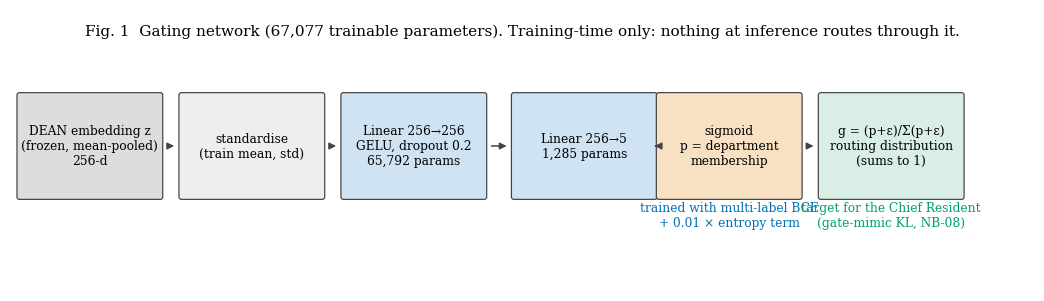

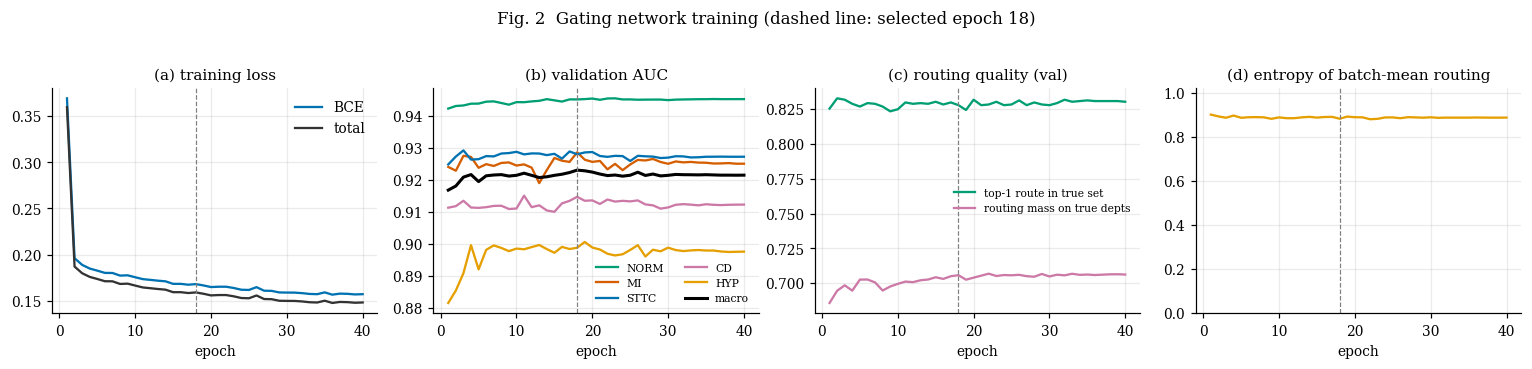

In [11]:
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(12, 3.3))
ax.set_xlim(0, 12); ax.set_ylim(0, 3.3); ax.axis('off'); ax.grid(False)
n1, n2 = D_IN * CFG['d_hidden'] + CFG['d_hidden'], CFG['d_hidden'] * 5 + 5
boxes = [
    (0.1, 'DEAN embedding z\n(frozen, mean-pooled)\n%d-d' % D_IN, '#dddddd'),
    (2.0, 'standardise\n(train mean, std)', '#eeeeee'),
    (3.9, 'Linear %d→%d\nGELU, dropout %.1f\n%s params' % (D_IN, CFG['d_hidden'], CFG['drop'], f'{n1:,}'), '#cfe3f3'),
    (5.9, 'Linear %d→5\n%s params' % (CFG['d_hidden'], f'{n2:,}'), '#cfe3f3'),
    (7.6, 'sigmoid\np = department\nmembership', '#f7e1c2'),
    (9.5, 'g = (p+ε)/Σ(p+ε)\nrouting distribution\n(sums to 1)', '#d9efe6'),
]
for x0, txt, fc in boxes:
    ax.add_patch(FancyBboxPatch((x0, 1.1), 1.65, 1.2, boxstyle='round,pad=0.03', fc=fc, ec='#444444', lw=0.8))
    ax.text(x0 + 0.825, 1.7, txt, ha='center', va='center', fontsize=8)
for (x0, _, _), (x1, _, _) in zip(boxes[:-1], boxes[1:]):
    ax.add_patch(FancyArrowPatch((x0 + 1.7, 1.7), (x1 - 0.05, 1.7), arrowstyle='-|>', mutation_scale=9, color='#444444'))
ax.text(7.6 + 0.825, 0.75, 'trained with multi-label BCE\n+ %.2f × entropy term' % CFG['ent_weight'], ha='center', fontsize=8, color='#0072B2')
ax.text(9.5 + 0.825, 0.75, 'target for the Chief Resident\n(gate-mimic KL, NB-08)', ha='center', fontsize=8, color='#009E73')
ax.text(6.0, 3.0, 'Fig. 1  Gating network (%s trainable parameters). Training-time only: nothing at inference routes through it.' % f'{n1 + n2:,}', ha='center', fontsize=10)
save_fig(fig, 'fig01_gating_architecture')

# training curves, final run + seed spread of the same configuration (from the ablation below, filled in later)
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2))
axes[0].plot(hist.epoch, hist.bce, color='#0072B2', label='BCE'); axes[0].plot(hist.epoch, hist.loss, color='#333', label='total')
axes[0].set_title('(a) training loss'); axes[0].legend()
for d in DEPTS:
    axes[1].plot(hist.epoch, hist[f'auc_{d}'], color=COL[d], label=d)
axes[1].plot(hist.epoch, hist.val_macro_auc, color='k', lw=2, label='macro'); axes[1].set_title('(b) validation AUC'); axes[1].legend(fontsize=7, ncol=2)
axes[2].plot(hist.epoch, hist.top1_in_true, color='#009E73', label='top-1 route in true set')
axes[2].plot(hist.epoch, hist.mass_on_true, color='#CC79A7', label='routing mass on true depts'); axes[2].set_title('(c) routing quality (val)'); axes[2].legend(fontsize=7)
axes[3].plot(hist.epoch, hist.entropy_batch_mean, color='#E69F00'); axes[3].set_title('(d) entropy of batch-mean routing'); axes[3].set_ylim(0, 1.02)
for a in axes:
    a.set_xlabel('epoch'); a.axvline(final['best_epoch'], ls='--', color='gray', lw=0.8)
fig.suptitle(f'Fig. 2  Gating network training (dashed line: selected epoch {final["best_epoch"]})', y=1.03)
fig.tight_layout()
save_fig(fig, 'fig02_gating_training')

## 9. Figures: discrimination, calibration and routing behaviour

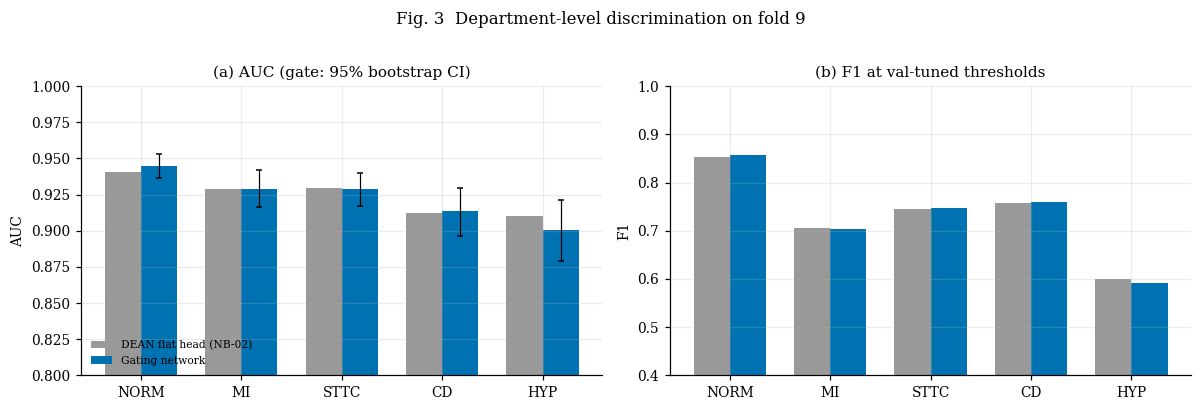

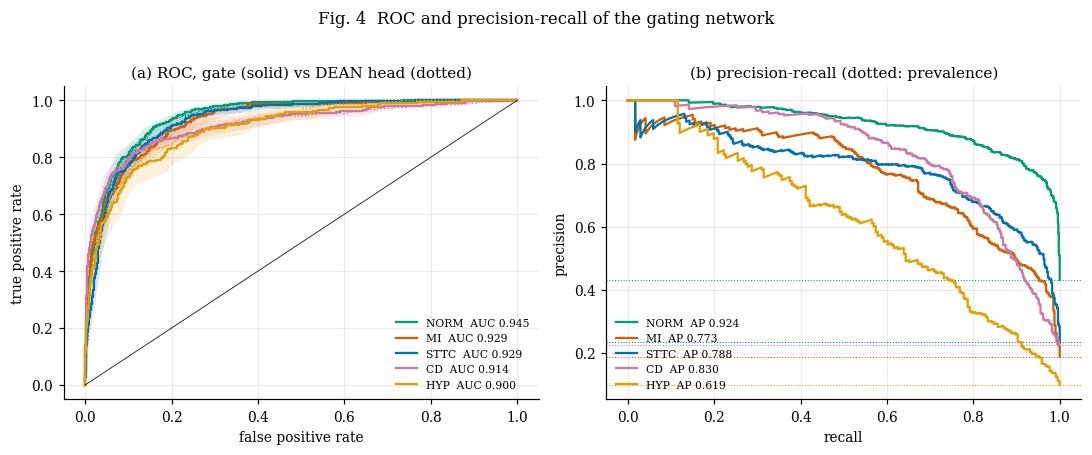

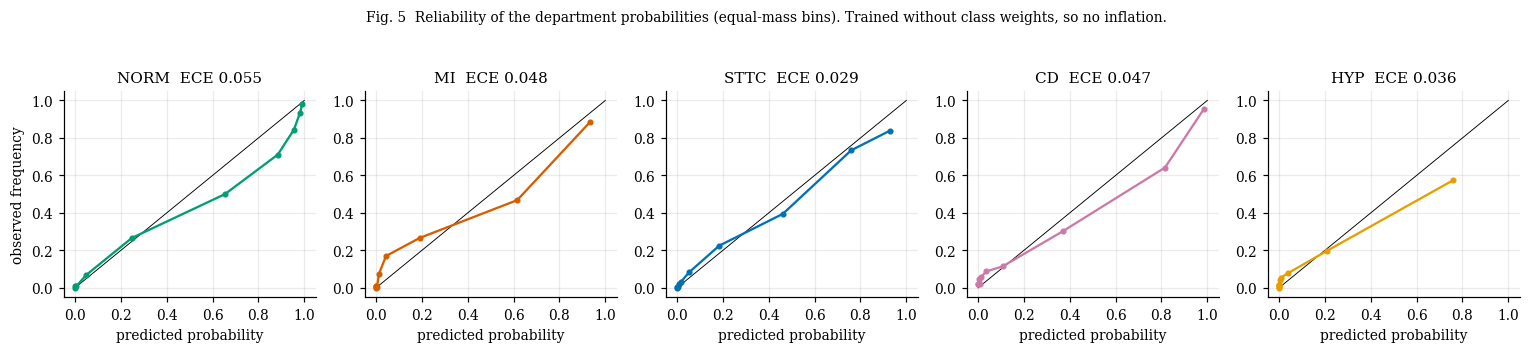

In [12]:
from sklearn.metrics import roc_curve, precision_recall_curve, average_precision_score

# per-department AUC / F1 against the DEAN head
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
x = np.arange(5); w = 0.36
for k, (nm, p, colr) in enumerate([('DEAN flat head (NB-02)', P_head_va, '#999999'), ('Gating network', P_va, '#0072B2')]):
    a = auc_per_label(Yva, p, 1)
    axes[0].bar(x + (k - 0.5) * w, a, w, color=colr, label=nm)
    f1 = f1_at(Yva, p, thr_head if k == 0 else THR)
    axes[1].bar(x + (k - 0.5) * w, f1, w, color=colr, label=nm)
lo, hi = PL.auc_lo.values, PL.auc_hi.values
axes[0].errorbar(x + 0.5 * w, PL.auc.values, yerr=[PL.auc.values - lo, hi - PL.auc.values], fmt='none', color='k', lw=0.8, capsize=2)
for a_, ttl, yl in [(axes[0], '(a) AUC (gate: 95% bootstrap CI)', 'AUC'), (axes[1], '(b) F1 at val-tuned thresholds', 'F1')]:
    a_.set_xticks(x); a_.set_xticklabels(DEPTS); a_.set_title(ttl); a_.set_ylabel(yl)
axes[0].set_ylim(0.8, 1.0); axes[1].set_ylim(0.4, 1.0); axes[0].legend(fontsize=7, loc='lower left')
fig.suptitle('Fig. 3  Department-level discrimination on fold 9', y=1.02)
fig.tight_layout()
save_fig(fig, 'fig03_dept_auc_f1')

# ROC with bootstrap band and PR
fpr_grid = np.linspace(0, 1, 101)
rng2 = np.random.default_rng(1)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for j, d in enumerate(DEPTS):
    f, t, _ = roc_curve(Yva[:, j], P_va[:, j])
    tb = []
    for _ in range(150):
        ii = rng2.integers(0, len(Yva), len(Yva))
        if Yva[ii, j].sum() in (0, len(ii)):
            continue
        fb, tb_, _ = roc_curve(Yva[ii, j], P_va[ii, j])
        tb.append(np.interp(fpr_grid, fb, tb_))
    lo_, hi_ = np.percentile(tb, [2.5, 97.5], axis=0)
    axes[0].plot(f, t, color=COL[d], label=f'{d}  AUC {PL.auc[j]:.3f}')
    axes[0].fill_between(fpr_grid, lo_, hi_, color=COL[d], alpha=0.15, lw=0)
    fh, th_, _ = roc_curve(Yva[:, j], P_head_va[:, j])
    axes[0].plot(fh, th_, color=COL[d], ls=':', lw=0.9)
    pr, rc, _ = precision_recall_curve(Yva[:, j], P_va[:, j])
    axes[1].plot(rc, pr, color=COL[d], label=f'{d}  AP {PL.ap[j]:.3f}')
    axes[1].axhline(Yva[:, j].mean(), color=COL[d], ls=':', lw=0.7)
axes[0].plot([0, 1], [0, 1], color='k', lw=0.5)
axes[0].set_xlabel('false positive rate'); axes[0].set_ylabel('true positive rate'); axes[0].set_title('(a) ROC, gate (solid) vs DEAN head (dotted)')
axes[1].set_xlabel('recall'); axes[1].set_ylabel('precision'); axes[1].set_title('(b) precision-recall (dotted: prevalence)')
axes[0].legend(fontsize=7, loc='lower right'); axes[1].legend(fontsize=7, loc='lower left')
fig.suptitle('Fig. 4  ROC and precision-recall of the gating network', y=1.02)
fig.tight_layout()
save_fig(fig, 'fig04_roc_pr')

# calibration of the membership probabilities
fig, axes = plt.subplots(1, 5, figsize=(14, 3))
ece_d = {}
for ax, (j, d) in zip(axes, enumerate(DEPTS)):
    conf, accu, e = reliability(Yva[:, j], P_va[:, j], 10)
    ece_d[d] = e
    ax.plot([0, 1], [0, 1], color='k', lw=0.6); ax.plot(conf, accu, 'o-', color=COL[d], ms=3)
    ax.set_title(f'{d}  ECE {e:.3f}'); ax.set_xlabel('predicted probability')
axes[0].set_ylabel('observed frequency')
fig.suptitle('Fig. 5  Reliability of the department probabilities (equal-mass bins). Trained without class weights, so no inflation.', y=1.05, fontsize=9)
fig.tight_layout()
save_fig(fig, 'fig05_calibration')

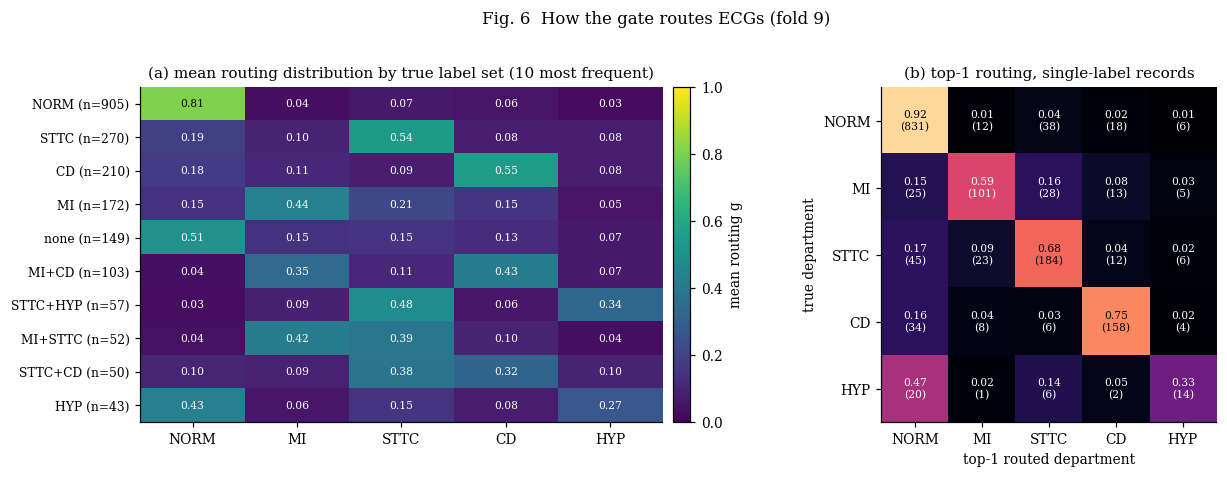

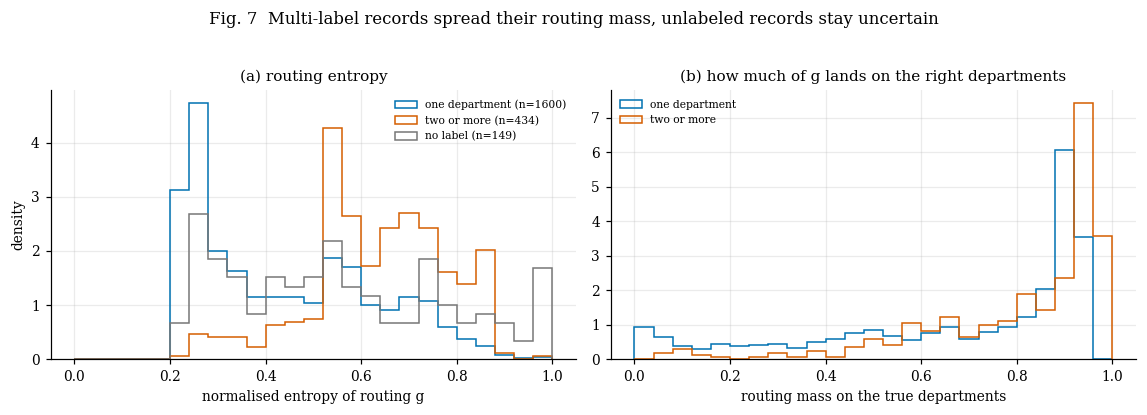

In [13]:
# what the routing distribution looks like for each ground-truth label set
names = np.array(['+'.join(DEPTS[j] for j in np.where(Yva[i] > 0)[0]) or 'none' for i in range(len(Yva))])
order = pd.Series(names).value_counts()
keep = list(order.index[:10])
M = np.array([G_va[names == k].mean(0) for k in keep])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={'width_ratios': [1.1, 1]})
ax = axes[0]
im = ax.imshow(M, cmap='viridis', vmin=0, vmax=1, aspect='auto'); ax.grid(False)
for r in range(M.shape[0]):
    for c in range(5):
        ax.text(c, r, f'{M[r, c]:.2f}', ha='center', va='center', fontsize=7, color='w' if M[r, c] < 0.55 else 'k')
ax.set_xticks(range(5)); ax.set_xticklabels(DEPTS); ax.set_yticks(range(len(keep))); ax.set_yticklabels([f'{k} (n={order[k]})' for k in keep], fontsize=8)
fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02, label='mean routing g')
ax.set_title('(a) mean routing distribution by true label set (10 most frequent)')

single = np.where(Yva.sum(1) == 1)[0]
true1 = Yva[single].argmax(1)
top1 = G_va[single].argmax(1)
cm = np.zeros((5, 5))
for t_, p_ in zip(true1, top1):
    cm[t_, p_] += 1
cmn = cm / cm.sum(1, keepdims=True)
ax = axes[1]
im = ax.imshow(cmn, cmap='magma', vmin=0, vmax=1); ax.grid(False)
for r in range(5):
    for c in range(5):
        ax.text(c, r, f'{cmn[r, c]:.2f}\n({int(cm[r, c])})', ha='center', va='center', fontsize=7, color='w' if cmn[r, c] < 0.6 else 'k')
ax.set_xticks(range(5)); ax.set_xticklabels(DEPTS); ax.set_yticks(range(5)); ax.set_yticklabels(DEPTS)
ax.set_xlabel('top-1 routed department'); ax.set_ylabel('true department'); ax.set_title('(b) top-1 routing, single-label records')
fig.suptitle('Fig. 6  How the gate routes ECGs (fold 9)', y=1.02)
fig.tight_layout()
save_fig(fig, 'fig06_routing_heatmap_confusion')

# entropy of the routing distribution and the mass it puts on the right departments
H_va = entropy_np(G_va) / LOG5
nl = Yva.sum(1)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6))
bins = np.linspace(0, 1, 26)
for lab, mask, colr in [('one department', nl == 1, '#0072B2'), ('two or more', nl >= 2, '#D55E00'), ('no label', nl == 0, '#777777')]:
    if mask.any():
        axes[0].hist(H_va[mask], bins=bins, histtype='step', lw=1.6, density=True, color=colr, label=f'{lab} (n={int(mask.sum())})')
axes[0].set_xlabel('normalised entropy of routing g'); axes[0].set_ylabel('density'); axes[0].legend(fontsize=7); axes[0].set_title('(a) routing entropy')
mass = (G_va * Yva).sum(1)
for lab, mask, colr in [('one department', nl == 1, '#0072B2'), ('two or more', nl >= 2, '#D55E00')]:
    if mask.any():
        axes[1].hist(mass[mask], bins=np.linspace(0, 1, 26), histtype='step', lw=1.6, density=True, color=colr, label=lab)
axes[1].set_xlabel('routing mass on the true departments'); axes[1].legend(fontsize=7); axes[1].set_title('(b) how much of g lands on the right departments')
fig.suptitle('Fig. 7  Multi-label records spread their routing mass, unlabeled records stay uncertain', y=1.03)
fig.tight_layout()
save_fig(fig, 'fig07_routing_entropy')

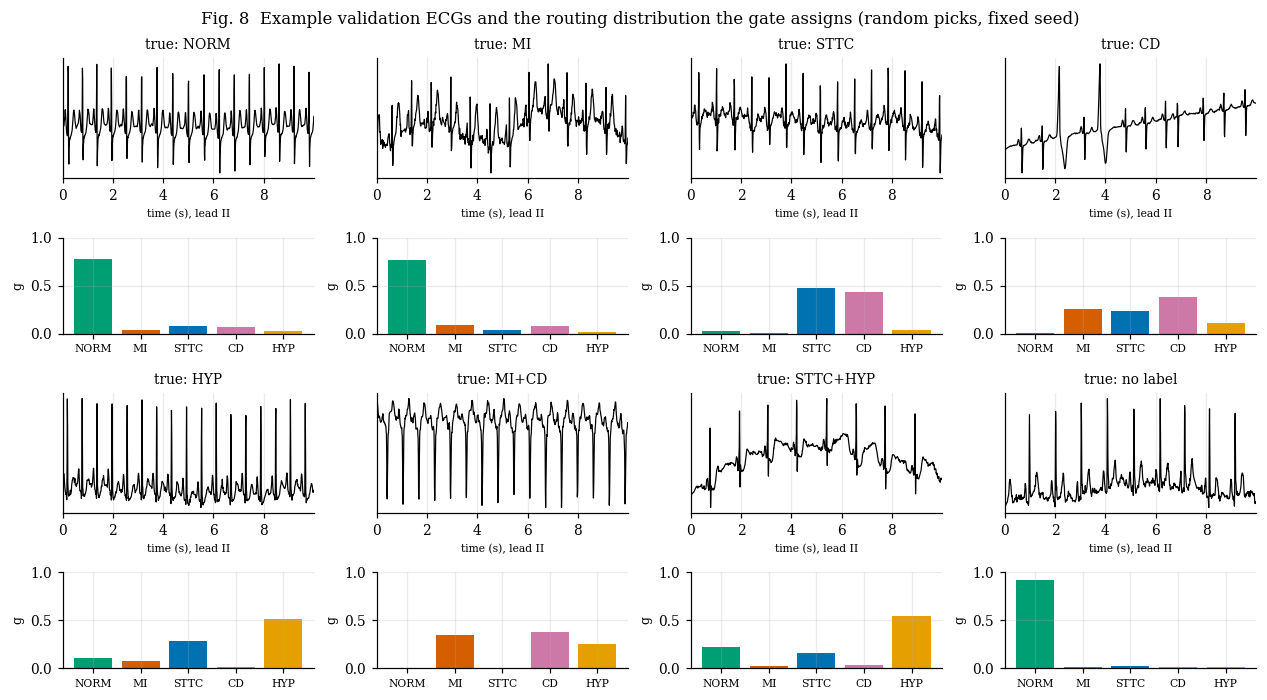

In [14]:
# example ECGs with their routing distribution
sig_arr = np.load(find_one('ptbxl_100hz.npy'), mmap_mode='r')
if sig_arr.ndim == 3 and sig_arr.shape[1] != 12 and sig_arr.shape[2] == 12:
    sig_arr = np.transpose(sig_arr, (0, 2, 1))
rg = np.random.default_rng(3)
picks = []
for j, d in enumerate(DEPTS):
    pool = np.where((nl == 1) & (Yva[:, j] == 1))[0]
    if len(pool): picks.append((int(rg.choice(pool)), d))
for k in [k for k in order.index if '+' in k][:2]:
    pool = np.where(names == k)[0]
    picks.append((int(rg.choice(pool)), k))
pool = np.where(nl == 0)[0]
if len(pool): picks.append((int(rg.choice(pool)), 'no label'))
picks = picks[:8]
ncol = 4
nrow = math.ceil(len(picks) / ncol)
fig = plt.figure(figsize=(14, 3.6 * nrow))
gs = fig.add_gridspec(2 * nrow, ncol, height_ratios=[1.0, 0.8] * nrow, hspace=0.55, wspace=0.25)
t_ax = np.arange(sig_arr.shape[2]) / 100
for n_, (i, lab) in enumerate(picks):
    r, c = divmod(n_, ncol)
    ax = fig.add_subplot(gs[2 * r, c])
    ax.plot(t_ax, np.asarray(sig_arr[va_idx[i], 1]), color='k', lw=0.8)
    ax.set_title(f'true: {lab}', fontsize=9); ax.set_yticks([]); ax.margins(x=0); ax.set_xlabel('time (s), lead II', fontsize=7)
    ax2 = fig.add_subplot(gs[2 * r + 1, c])
    ax2.bar(range(5), G_va[i], color=[COL[d] for d in DEPTS])
    ax2.set_xticks(range(5)); ax2.set_xticklabels(DEPTS, fontsize=7); ax2.set_ylim(0, 1); ax2.set_ylabel('g', fontsize=8)
fig.suptitle('Fig. 8  Example validation ECGs and the routing distribution the gate assigns (random picks, fixed seed)', y=0.94)
save_fig(fig, 'fig08_routing_examples')

## 10. Cross-fitted routing for the training records, and the in-sample gap
The routing distribution of a training record is a distillation target, so it should look like what the gate says about an ECG it has not trained on. Four gates are trained, each on six folds, and each predicts the two folds it did not see. The result is saved as `routing_distributions.npy`.

One limit remains and is measured here, not hidden: the DEAN embeddings of the training records come from a teacher that was fine-tuned on them. Cross-fitting removes the gate's own memorisation, not the teacher's. The gap table shows how much sharper the in-sample numbers are.

group (1, 2): trained on 13062, predicted 4356, best epoch 9, held-out macro-AUC 0.9685
group (3, 4): trained on 13052, predicted 4366, best epoch 4, held-out macro-AUC 0.9675
group (5, 6): trained on 13071, predicted 4347, best epoch 12, held-out macro-AUC 0.9682
group (7, 8): trained on 13069, predicted 4349, best epoch 6, held-out macro-AUC 0.9674
                                             gate macro-AUC  gate top-1 in true set  gate mass on true depts  gate entropy (single-label)  DEAN head macro-AUC
train, in-sample gate + in-sample embedding           0.977                   0.919                    0.777                        0.414                0.968
train, cross-fitted gate                              0.968                   0.903                    0.761                        0.427                0.920
validation (fold 9)                                   0.923                   0.831                    0.704                        0.439                0.924


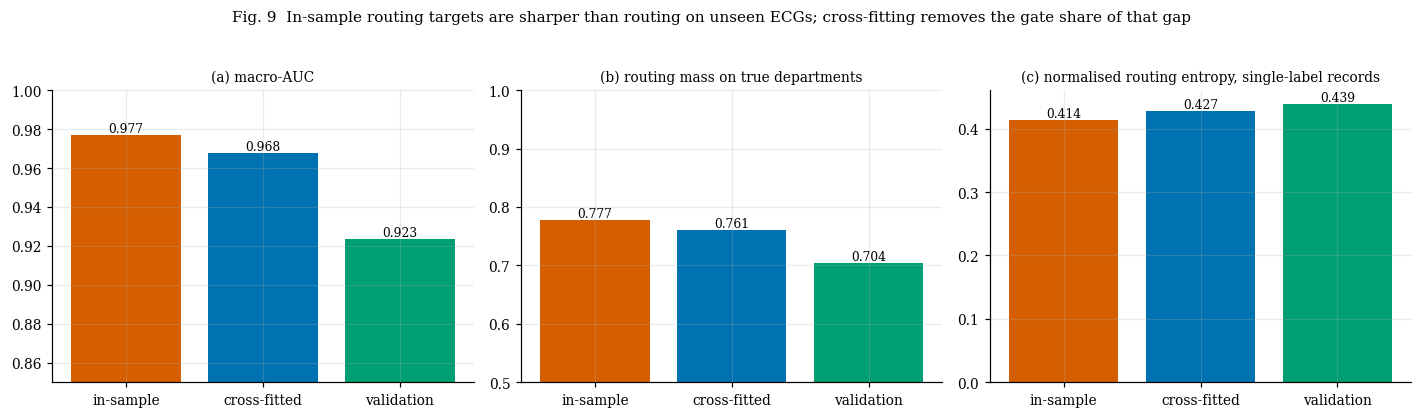

In [15]:
P_tr_oof = np.zeros((len(tr_idx), 5), dtype=np.float32)
oof_rows = []
for k, grp in enumerate(CFG['crossfit_groups']):
    held = np.isin(fold_tr, grp)
    r = train_gate(Ztr[~held], Ytr[~held], Zva, Yva, CFG, CFG['ent_weight'], CFG['ent_mode'], CFG['seed'] + 1 + k, soft=S_tr[~held])
    P_tr_oof[held] = gate_probs(r['model'], Ztr[held])
    a = auc_per_label(Ytr[held], P_tr_oof[held], 1)
    oof_rows.append(dict(group=str(grp), n_train=int((~held).sum()), n_held=int(held.sum()), best_epoch=r['best_epoch'], held_out_macro_auc=float(np.nanmean(a))))
    print(f'group {grp}: trained on {int((~held).sum())}, predicted {int(held.sum())}, best epoch {r["best_epoch"]}, held-out macro-AUC {np.nanmean(a):.4f}')
G_tr_oof = routing_np(P_tr_oof, CFG['route_eps'])
assert np.isfinite(G_tr_oof).all() and np.allclose(G_tr_oof.sum(1), 1, atol=1e-5)

def gap_row(Y, p_gate, lg_head):
    a = auc_per_label(Y, p_gate, 1)
    rm = route_metrics(Y, p_gate)
    ah = auc_per_label(Y, sigmoid(lg_head), 1)
    return {'gate macro-AUC': float(np.nanmean(a)), 'gate top-1 in true set': rm['top1_in_true'], 'gate mass on true depts': rm['mass_on_true'],
            'gate entropy (single-label)': rm['entropy_single'], 'DEAN head macro-AUC': float(np.nanmean(ah))}
GAP = pd.DataFrame({'train, in-sample gate + in-sample embedding': gap_row(Ytr, P_tr_in, LG_tr),
                    'train, cross-fitted gate': gap_row(Ytr, P_tr_oof, LG_oof),
                    'validation (fold 9)': gap_row(Yva, P_va, LG_va)}).T
print(GAP.round(3).to_string())
GAP.to_csv(os.path.join(WORK, 'gating_generalisation_gap.csv'))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
cols3 = ['#D55E00', '#0072B2', '#009E73']
labs3 = ['in-sample', 'cross-fitted', 'validation']
for ax, key, ttl in zip(axes, ['gate macro-AUC', 'gate mass on true depts', 'gate entropy (single-label)'],
                        ['(a) macro-AUC', '(b) routing mass on true departments', '(c) normalised routing entropy, single-label records']):
    ax.bar(range(3), GAP[key].values, color=cols3)
    for i_, v in enumerate(GAP[key].values):
        ax.text(i_, v, f'{v:.3f}', ha='center', va='bottom', fontsize=8)
    ax.set_xticks(range(3)); ax.set_xticklabels(labs3); ax.set_title(ttl, fontsize=9)
axes[0].set_ylim(0.85, 1.0); axes[1].set_ylim(0.5, 1.0)
fig.suptitle('Fig. 9  In-sample routing targets are sharper than routing on unseen ECGs; cross-fitting removes the gate share of that gap', y=1.04, fontsize=10)
fig.tight_layout()
save_fig(fig, 'fig09_insample_gap')

## 11. Ablation: the entropy term
Four settings, five seeds each, same data, same epochs. The row marked "used" is the final configuration. The "literal" row is the plan's wording read as a per-sample entropy penalty. With five seeds the table shows whether a difference is larger than the seed-to-seed noise; if it is not, the honest reading is that the term does little, and we say so.

ablation: 20 runs in 271s
                                macro_auc   top1_in_true   mass_on_true entropy_single  entropy_multi   entropy_none entropy_batch_mean
setting                                                                                                                                
no entropy term             0.922 ± 0.000  0.829 ± 0.002  0.701 ± 0.002  0.446 ± 0.008  0.641 ± 0.005  0.561 ± 0.008      0.886 ± 0.004
batch-mean, 0.01 (used)     0.922 ± 0.000  0.829 ± 0.002  0.700 ± 0.002  0.446 ± 0.008  0.641 ± 0.005  0.562 ± 0.008      0.887 ± 0.004
batch-mean, 0.05            0.922 ± 0.000  0.829 ± 0.002  0.699 ± 0.002  0.449 ± 0.008  0.642 ± 0.005  0.567 ± 0.008      0.890 ± 0.004
per-sample, 0.01 (literal)  0.922 ± 0.000  0.829 ± 0.002  0.702 ± 0.002  0.442 ± 0.007  0.639 ± 0.005  0.557 ± 0.007      0.886 ± 0.003


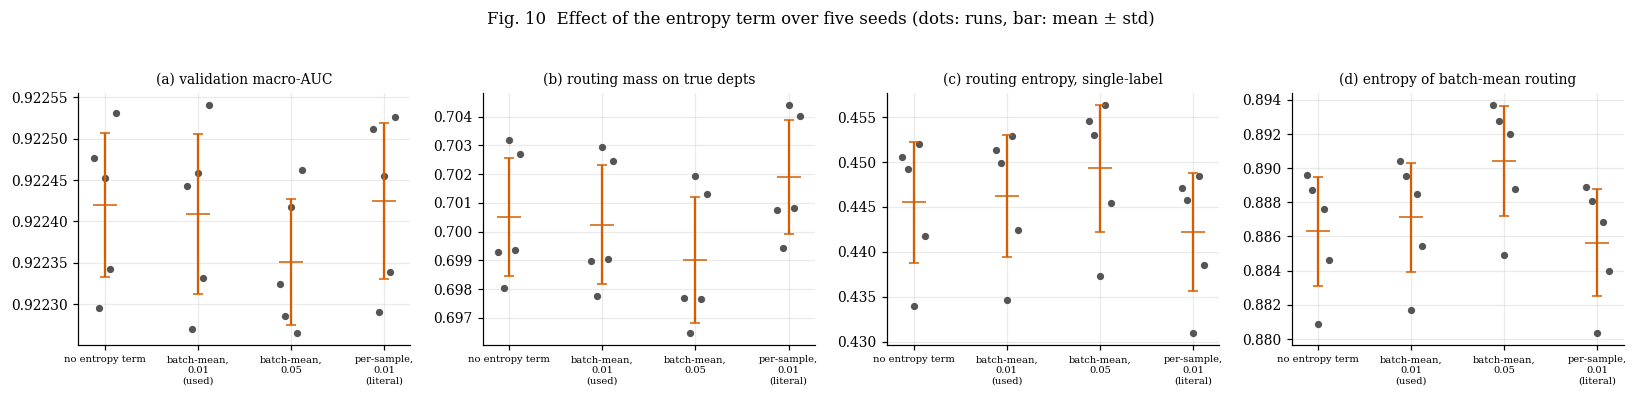

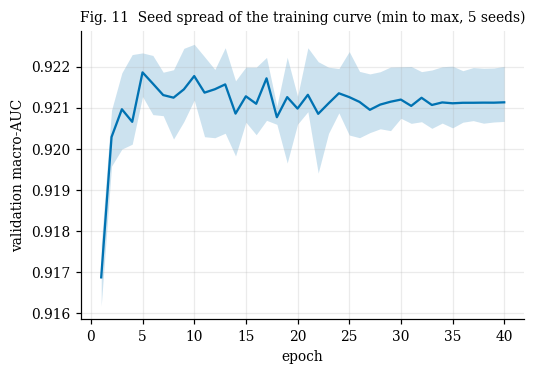

In [16]:
ABL = [('no entropy term', 0.0, 'batch'), ('batch-mean, 0.01 (used)', 0.01, 'batch'),
       ('batch-mean, 0.05', 0.05, 'batch'), ('per-sample, 0.01 (literal)', 0.01, 'sample')]
t0 = time.time()
abl_rows, abl_hist = [], {}
for nm, w_, mode in ABL:
    for s in CFG['ablation_seeds']:
        r = train_gate(Ztr, Ytr, Zva, Yva, CFG, w_, mode, s)
        pv = gate_probs(r['model'], Zva)
        rm = route_metrics(Yva, pv)
        abl_rows.append(dict(setting=nm, seed=s, macro_auc=r['best_auc'], best_epoch=r['best_epoch'], **{k: rm[k] for k in
                        ['top1_in_true', 'topk_exact', 'mass_on_true', 'entropy_single', 'entropy_multi', 'entropy_none', 'entropy_batch_mean']}))
        if nm == 'batch-mean, 0.01 (used)':
            abl_hist[s] = r['hist']
print(f'ablation: {len(abl_rows)} runs in {time.time() - t0:.0f}s')
ABL_DF = pd.DataFrame(abl_rows)
agg = ABL_DF.groupby('setting', sort=False).agg(['mean', 'std']).drop(columns='seed')
tab_abl = pd.DataFrame({m: [f'{agg.loc[s, (m, "mean")]:.3f} ± {agg.loc[s, (m, "std")]:.3f}' for s in agg.index] for m in
                        ['macro_auc', 'top1_in_true', 'mass_on_true', 'entropy_single', 'entropy_multi', 'entropy_none', 'entropy_batch_mean']}, index=agg.index)
print(tab_abl.to_string())
tab_abl.to_csv(os.path.join(WORK, 'gating_ablation.csv'))
ABL_DF.to_csv(os.path.join(WORK, 'gating_ablation_runs.csv'), index=False)

fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
settings = list(agg.index)
for ax, m, ttl in zip(axes, ['macro_auc', 'mass_on_true', 'entropy_single', 'entropy_batch_mean'],
                      ['(a) validation macro-AUC', '(b) routing mass on true depts', '(c) routing entropy, single-label', '(d) entropy of batch-mean routing']):
    for k, s in enumerate(settings):
        v = ABL_DF[ABL_DF.setting == s][m].values
        ax.scatter(np.full(len(v), k) + np.linspace(-0.12, 0.12, len(v)), v, s=14, color='#555555', zorder=3)
        ax.errorbar(k, v.mean(), yerr=v.std(), fmt='_', color='#D55E00', ms=16, capsize=3, zorder=4)
    ax.set_xticks(range(len(settings))); ax.set_xticklabels([s.replace(', ', ',\n').replace(' (', '\n(') for s in settings], fontsize=6.5); ax.set_title(ttl, fontsize=9)
fig.suptitle('Fig. 10  Effect of the entropy term over five seeds (dots: runs, bar: mean ± std)', y=1.04)
fig.tight_layout()
save_fig(fig, 'fig10_entropy_ablation')

# seed spread of the training curve of the used configuration
fig, ax = plt.subplots(figsize=(5.2, 3.4))
H_ = np.stack([abl_hist[s].val_macro_auc.values for s in abl_hist])
ep_ = np.arange(1, H_.shape[1] + 1)
ax.plot(ep_, H_.mean(0), color='#0072B2'); ax.fill_between(ep_, H_.min(0), H_.max(0), color='#0072B2', alpha=0.2, lw=0)
ax.set_xlabel('epoch'); ax.set_ylabel('validation macro-AUC'); ax.set_title('Fig. 11  Seed spread of the training curve (min to max, 5 seeds)', fontsize=9)
save_fig(fig, 'fig11_seed_spread')

## 12. Export
Row order of every array is the row order of `split_idx.npz`. `routing_distributions.npy` is the cross-fitted version, which is the one the distillation notebooks should use as the target. The in-sample version is kept only for comparison.

In [17]:
np.save(os.path.join(WORK, 'routing_distributions.npy'), G_tr_oof)
np.save(os.path.join(WORK, 'routing_distributions_insample.npy'), G_tr_in)
np.save(os.path.join(WORK, 'routing_val.npy'), G_va)
np.save(os.path.join(WORK, 'routing_probs_train_oof.npy'), P_tr_oof)
np.save(os.path.join(WORK, 'routing_probs_train_insample.npy'), P_tr_in)
np.save(os.path.join(WORK, 'routing_probs_val.npy'), P_va)

torch.save({
    'member_states': [m.state_dict() for m in members], 'arch': {k: CFG[k] for k in ['d_hidden', 'drop', 'n_layers']},
    'd_in': D_IN, 'route_eps': CFG['route_eps'],
    'departments': DEPTS, 'thresholds': THR.tolist(), 'ent_weight': CFG['ent_weight'], 'ent_mode': CFG['ent_mode'],
    'best_epochs': [int(f['best_epoch']) for f in finals], 'seed': CFG['seed'], 'chosen_setting': CHOSEN, 'embedding_source': 'dean_emb_*.npy from NB-02 revision 2',
}, os.path.join(WORK, 'gating.pt'))

metrics = {
    'note': 'validation fold only (fold 9). Thresholds tuned on this fold, so F1 is optimistic. Best epoch was selected on fold 9. Test numbers come from NB-09.',
    'n_params': int(sum(p.numel() for p in gate.parameters())), 'best_epochs': [int(f['best_epoch']) for f in finals], 'chosen_setting': CHOSEN, 'n_members': len(members),
    'bootstrap_95ci': {nm: {k: v for k, v in b.items() if not k.startswith('label_')} for nm, b in BOOT.items()},
    'paired_auc_gate_minus_head': d_auc, 'routing_val': RM, 'ece_val': ece_d,
    'per_dept': PL.round(4).to_dict(orient='records'), 'crossfit': oof_rows,
    'generalisation_gap': GAP.round(4).to_dict(orient='index'),
    'ablation_mean': {s: {m: float(agg.loc[s, (m, 'mean')]) for m in ['macro_auc', 'top1_in_true', 'mass_on_true', 'entropy_single', 'entropy_batch_mean']} for s in agg.index},
}
json.dump(metrics, open(os.path.join(WORK, 'gating_metrics.json'), 'w'), indent=2)
json.dump({'CFG': CFG, 'versions': VERSIONS}, open(os.path.join(WORK, 'gating_config.json'), 'w'), indent=2)

# reload check: the saved file reproduces the validation probabilities
g2, _ = load_gate(os.path.join(WORK, 'gating.pt'), dev)
assert np.allclose(gate_probs(g2, Zva), P_va, atol=1e-6), 'saved gate does not reproduce the validation outputs'
print('saved gate reloads and reproduces the validation outputs')
print(f'total notebook time {(time.time() - NB_T0) / 60:.1f} min')
for root, _, files in os.walk(WORK):
    for f in sorted(files):
        p = os.path.join(root, f)
        if '__pycache__' in p or p.endswith('.tmp'):
            continue
        print(f'  {os.path.relpath(p, WORK):45s} {os.path.getsize(p) / 1e6:8.2f} MB')

saved gate reloads and reproduces the validation outputs
total notebook time 15.2 min
  __notebook__.ipynb                                1.17 MB
  eval_lib.py                                       0.01 MB
  gating.pt                                         1.36 MB
  gating_ablation.csv                               0.00 MB
  gating_ablation_runs.csv                          0.00 MB
  gating_config.json                                0.00 MB
  gating_generalisation_gap.csv                     0.00 MB
  gating_lib.py                                     0.00 MB
  gating_metrics.json                               0.01 MB
  gating_per_dept.csv                               0.00 MB
  gating_sweep.csv                                  0.00 MB
  gating_val_table.csv                              0.00 MB
  gating_val_table.tex                              0.00 MB
  routing_distributions.npy                         0.35 MB
  routing_distributions_insample.npy                0.35 MB
  routing_prob

## 13. After this notebook
1. Save a version, then create the Dataset **`gating-network-v1`** from the output (`gating.pt`, `gating_lib.py`, `gating_sweep.csv`, `routing_distributions.npy` and the other `routing_*.npy` files, `gating_metrics.json`).
2. NB-07 collects `routing_distributions.npy` as the training target for the gate-mimic loss. In NB-08 the student's own routing is built with the same function (`gating_lib.routing_np` or `routing_t`): the student's per-department probabilities, plus ε, normalised to sum to one.
3. The numbers worth carrying forward are in `gating_metrics.json`: macro-AUC against the DEAN flat head, the routing mass on the true departments, and the in-sample gap. If the gate is clearly below the flat head, say so in the paper; if it matches it, the routing target is as informative as the teacher's own superclass output.
4. Test-fold numbers for the gate are computed in NB-09 with the thresholds saved in `gating.pt`.
5. In NB-07/08/09 rebuild the gate with `gating_lib.load_gate('gating.pt')` (handles the ensemble); the old `GatingNet(...).load_state_dict(ck['state_dict'])` no longer applies.